# Análisis exploratorio y auditoría de Sartorius

En este capítulo caracterizamos las 606 imágenes anotadas de Sartorius antes de modelar. Cada análisis aparece global y estratificado por tipo celular, y cada hallazgo termina en una decisión de diseño. El notebook solo lee resultados guardados en `results/eda/seg/`; los genera `python scripts/eda.py seg` y las figuras con imágenes, `python scripts/figs_eda_seg.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display

from project.book_utils import CELL_COLORS, CELL_NAMES, need, style

style()
pd.set_option("display.precision", 3)
images = need("eda/seg/images.pkl")
TYPES = ["shsy5y", "astro", "cort"]
images["tipo"] = images.cell_type.map(CELL_NAMES)

## Carga, esquema e integridad

Leímos las imágenes PNG con PIL y las anotaciones del CSV de entrenamiento. Todas las imágenes tienen un solo canal de 8 bits y el mismo tamaño, 520 × 704 píxeles, por lo que el histograma de alto y ancho se reduce a un punto. La tabla siguiente resume el esquema verificado.

In [2]:
schema = pd.DataFrame({
    "verificación": ["imágenes", "tamaños distintos (alto × ancho)", "tipo de dato", "instancias anotadas",
                     "sample_id distintos", "fechas de placa distintas"],
    "valor": [len(images), images[["height", "width"]].drop_duplicates().shape[0], images.dtype.unique()[0],
              int(images.n_instances.sum()), images.sample_id.nunique(), images.sample_date.nunique()],
})
schema

,verificación,valor
0,imágenes,606
1,tamaños distintos (alto × ancho),1
2,tipo de dato,uint8
3,instancias anotadas,73585
4,sample_id distintos,403
5,fechas de placa distintas,18


Las pruebas de integridad están en `tests/test_data_splits.py` y se ejecutan con `pytest`. Un esquema de `pandera` exige identificadores no nulos, RLE con pares de enteros, ancho 704, alto 520 y tipo celular en {astro, cort, shsy5y}. El decodificador de RLE rechaza cualquier tramo fuera de la imagen. Las anotaciones se codifican en orden de filas (C) y con índice 1. La {numref}`fig-rle` muestra la validación visual: con orden de filas los contornos caen sobre las células, y con orden de columnas no.

```{figure} images/gen/seg_rle_validacion.png
:name: fig-rle
:width: 100%

*Decodificación de una imagen con las dos convenciones posibles de RLE.* Elaboración propia con datos de Sartorius.
```

Las anotaciones se solapan. Al construir el mapa de etiquetas asignamos cada píxel en disputa a la primera instancia del CSV. La tabla cuantifica el efecto por tipo celular.

In [3]:
ov = images.groupby("tipo").agg(imágenes=("n_instances", "size"),
                                 con_solape=("overlap_pixels", lambda s: (s > 0).mean()),
                                 píxeles_solapados_medios=("overlap_pixels", "mean"),
                                 instancias=("n_instances", "sum"), visibles=("n_visible", "sum"))
ov["ocultas"] = ov.instancias - ov.visibles
ov

,imágenes,con_solape,píxeles_solapados_medios,instancias,visibles,ocultas
tipo,,,,,,
Astrocitos,131,1.000,1849.069,10522,10515,7
Corticales,320,0.834,78.294,10777,10772,5
SH-SY5Y,155,1.000,1999.439,52286,52167,119


## Células por imagen

El conteo de células por imagen cambia un orden de magnitud entre tipos.

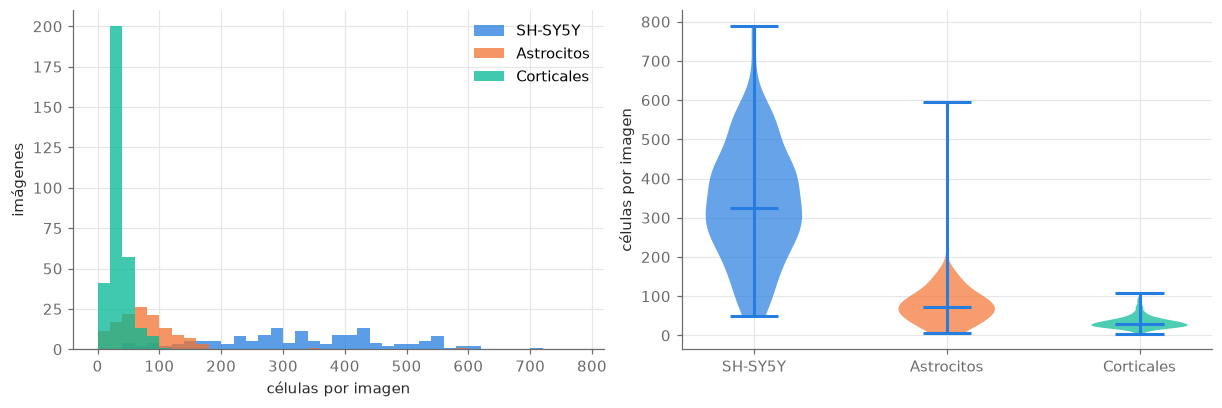

,count,mean,50%,min,max,proporción de imágenes,proporción de células
tipo,,,,,,,
Astrocitos,131.0,80.321,73.0,5.0,594.0,0.216,0.143
Corticales,320.0,33.678,30.0,4.0,108.0,0.528,0.146
SH-SY5Y,155.0,337.329,324.0,49.0,790.0,0.256,0.711


Gini del conteo global: **0.583**; coeficiente de variación: **1.25**.

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for t in TYPES:
    d = images[images.cell_type == t].n_instances
    axes[0].hist(d, bins=np.arange(0, 800, 20), alpha=0.75, color=CELL_COLORS[t], label=CELL_NAMES[t])
axes[0].set(xlabel="células por imagen", ylabel="imágenes"); axes[0].legend()
parts = axes[1].violinplot([images[images.cell_type == t].n_instances for t in TYPES], showmedians=True)
for b, t in zip(parts["bodies"], TYPES):
    b.set_facecolor(CELL_COLORS[t]); b.set_alpha(0.7)
axes[1].set_xticks([1, 2, 3], [CELL_NAMES[t] for t in TYPES]); axes[1].set_ylabel("células por imagen")
plt.show()

c = images.n_instances.to_numpy()
gini = (2 * np.arange(1, len(c) + 1) - len(c) - 1).dot(np.sort(c)) / (len(c) * c.sum())
tab = images.groupby("tipo").n_instances.describe()[["count", "mean", "50%", "min", "max"]]
tab["proporción de imágenes"] = tab["count"] / len(images)
tab["proporción de células"] = images.groupby("tipo").n_instances.sum() / c.sum()
display(tab)
display(Markdown(f"Gini del conteo global: **{gini:.3f}**; coeficiente de variación: **{c.std() / c.mean():.2f}**."))

Las neuronas corticales aportan el 53 % de las imágenes y solo el 15 % de las células. SH-SY5Y aporta el 26 % de las imágenes y el 71 % de las células. Como la métrica de Sartorius promedia por imagen, el resultado global pesa más a las corticales. Una métrica que promedie por instancia pesaría más a SH-SY5Y. Por eso reportamos siempre ambas lecturas estratificadas por tipo (H3).

## Área, forma y tamaño relativo al *stride*

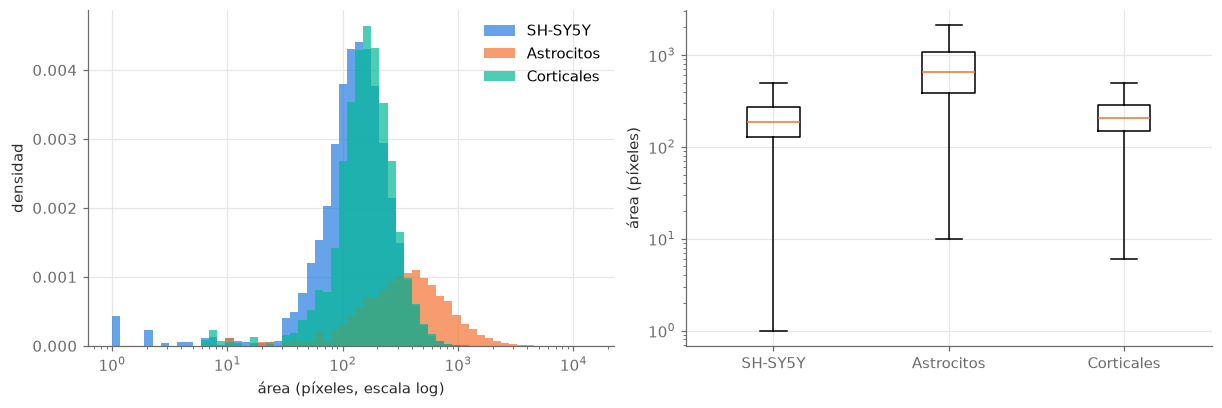

,p1,p5,p50,p95,p99,excentricidad (mediana),solidez (mediana)
cell_type,,,,,,,
Astrocitos,98.0,173.0,646.0,2345.0,4243.58,0.949,0.750
Corticales,57.0,94.0,206.0,494.0,734.00,0.683,0.942
SH-SY5Y,46.0,74.0,187.0,469.0,679.00,0.851,0.902


In [5]:
inst = need("eda/seg/instances.pkl")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
bins = np.logspace(0, np.log10(14000), 60)
for t in TYPES:
    a = inst[inst.cell_type == t].area
    axes[0].hist(a, bins=bins, alpha=0.7, color=CELL_COLORS[t], label=CELL_NAMES[t], density=True)
axes[0].set(xscale="log", xlabel="área (píxeles, escala log)", ylabel="densidad"); axes[0].legend()
axes[1].boxplot([inst[inst.cell_type == t].area for t in TYPES], showfliers=False)
axes[1].set_xticks([1, 2, 3], [CELL_NAMES[t] for t in TYPES]); axes[1].set(yscale="log", ylabel="área (píxeles)")
plt.show()
q = inst.groupby("cell_type").area.quantile([0.01, 0.05, 0.5, 0.95, 0.99]).unstack().rename(index=CELL_NAMES)
q.columns = ["p1", "p5", "p50", "p95", "p99"]
q["excentricidad (mediana)"] = inst.groupby("cell_type").eccentricity.median().rename(index=CELL_NAMES)
q["solidez (mediana)"] = inst.groupby("cell_type").solidity.median().rename(index=CELL_NAMES)
q

El área se ajusta mejor a una log-normal que a una gamma en los tres tipos: el AIC es menor y la prueba de Kolmogorov–Smirnov (submuestra de 2000 instancias) no rechaza la log-normal y sí la gamma.

In [6]:
fits = need("eda/seg/area_fits.pkl")
fits.assign(tipo=fits.cell_type.map(CELL_NAMES))[["tipo", "dist", "aic", "ks_stat", "ks_p"]]

,tipo,dist,aic,ks_stat,ks_p
0,Astrocitos,lognorm,160982.023,0.014,8.078e-01
1,Astrocitos,gamma,162041.907,0.054,1.432e-05
2,Corticales,lognorm,131380.535,0.026,1.422e-01
3,Corticales,gamma,131947.978,0.052,3.819e-05
4,SH-SY5Y,lognorm,635821.051,0.018,5.399e-01
5,SH-SY5Y,gamma,636891.899,0.046,3.710e-04


Los astrocitos son entre 3.1 y 3.5 veces más grandes en mediana (646 px) y mucho menos convexos (solidez 0.75) que las otras dos líneas, por sus prolongaciones largas. Con un *stride* de 32 píxeles en la salida más profunda de un *backbone*, una célula mediana de SH-SY5Y (187 px, unos 14 px de lado) queda dentro de una sola celda. Esto exige decodificar a resolución completa (U-Net++) o usar anclas pequeñas en el nivel más fino de la FPN (Mask R-CNN). El lado de la caja envolvente tiene percentiles 1, 50 y 99 de:

In [7]:
pd.Series(np.percentile(inst.bbox_side, [1, 5, 50, 95, 99]), index=["p1", "p5", "p50", "p95", "p99"]).round(1).to_frame("lado de caja (px)").T

,p1,p5,p50,p95,p99
lado de caja (px),8.5,11.0,18.8,53.9,88.8


Si reescaláramos las imágenes, las células más pequeñas desaparecerían. La tabla muestra la fracción de instancias que queda por debajo de 20 píxeles al llevar el lado corto (520) a cada resolución.

In [8]:
r = need("eda/seg/rescale_loss.pkl")
piv = r[r.min_pixels == 20].pivot_table(index="target", columns="cell_type", values="frac_below").rename(columns=CELL_NAMES)
(piv * 100).round(2).rename_axis("lado corto (px)").add_suffix(" (%)")

cell_type,Astrocitos (%),Corticales (%),SH-SY5Y (%)
lado corto (px),,,
256,0.62,3.21,7.32
384,0.09,0.22,0.42
512,0.03,0.10,0.12
520,0.02,0.10,0.12


## Intensidad, contraste y calidad de imagen

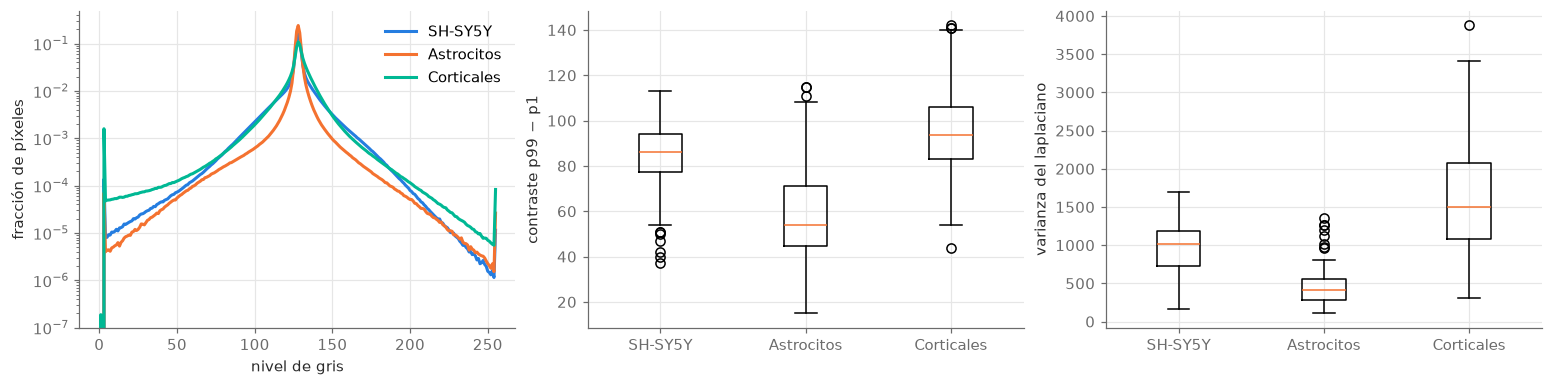

,media,contraste,SNR,enfoque,gradiente de iluminación,fracción saturada,cobertura
tipo,,,,,,,
Astrocitos,127.991,54.0,0.146,412.406,0.006,1.639e-05,0.176
Corticales,127.954,93.5,0.253,1500.560,0.016,6.556e-05,0.020
SH-SY5Y,127.970,86.0,0.228,1014.024,0.013,5.463e-06,0.200


In [9]:
hist = need("eda/seg/intensity_hist.pkl")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for t in TYPES:
    axes[0].plot(np.arange(256), hist[t], color=CELL_COLORS[t], label=CELL_NAMES[t])
axes[0].set(xlabel="nivel de gris", ylabel="fracción de píxeles", yscale="log", ylim=(1e-7, None)); axes[0].legend()
for ax, col, lab in ((axes[1], "contrast", "contraste p99 − p1"), (axes[2], "focus_lapvar", "varianza del laplaciano")):
    ax.boxplot([images[images.cell_type == t][col] for t in TYPES], showfliers=True)
    ax.set_xticks([1, 2, 3], [CELL_NAMES[t] for t in TYPES]); ax.set_ylabel(lab)
plt.show()
qual = images.groupby("tipo")[["mean", "contrast", "snr", "focus_lapvar", "illum_gradient", "saturated_frac", "coverage"]].median()
qual.columns = ["media", "contraste", "SNR", "enfoque", "gradiente de iluminación", "fracción saturada", "cobertura"]
qual

El contraste de fase produce un fondo gris casi constante (media cercana a 128) con bordes claros y oscuros alrededor de cada célula. Por eso la relación señal-ruido medida como diferencia de medias entre célula y fondo es baja (0.15 a 0.25): la información está en la textura y los halos, no en el brillo medio. Este hallazgo explica que un umbral de Otsu sobre intensidad no separe células y que el *baseline* clásico tenga que usar el gradiente.

Para marcar imágenes con artefactos usamos criterios explícitos, con umbrales en percentiles globales: enfoque bajo (varianza del laplaciano bajo el percentil 5), gradiente de iluminación alto (sobre el percentil 95) y saturación (más del 1 % de píxeles en 0 o 255).

In [10]:
flags = pd.DataFrame({
    "enfoque bajo": images.focus_lapvar < images.focus_lapvar.quantile(0.05),
    "iluminación no uniforme": images.illum_gradient > images.illum_gradient.quantile(0.95),
    "saturación > 1 %": images.saturated_frac > 0.01,
})
flags["alguno"] = flags.any(axis=1)
out = flags.groupby(images.tipo).mean().mul(100).round(1).add_suffix(" (%)")
out.loc["Global"] = flags.mean().mul(100).round(1).add_suffix(" (%)").values
out

,enfoque bajo (%),iluminación no uniforme (%),saturación > 1 % (%),alguno (%)
tipo,,,,
Astrocitos,19.8,0.8,0.0,20.6
Corticales,0.0,7.5,0.0,7.5
SH-SY5Y,3.2,3.9,0.0,7.1
Global,5.1,5.1,0.0,10.2


El enfoque bajo se concentra en los astrocitos, cuya varianza del laplaciano es la menor de los tres tipos. Los percentiles globales marcan un 5 % de imágenes por construcción. La pregunta útil es cómo se reparten esas imágenes: si se concentran en un tipo, ese tipo pesa más en las perturbaciones de desenfoque del capítulo de robustez.

## Muestra cualitativa

La fila superior de la {numref}`fig-cualitativa` muestra cinco imágenes elegidas al azar con semilla fija (2026). La fila inferior muestra los casos extremos: más y menos células, menor SNR, menor enfoque y mayor gradiente de iluminación.

```{figure} images/gen/seg_cualitativa.png
:name: fig-cualitativa
:width: 100%

*Muestra aleatoria (arriba) y casos extremos (abajo) con los contornos anotados.* Elaboración propia con datos de Sartorius.
```

## Densidad y contacto entre células

Construimos el grafo de adyacencia de cada imagen: dos células son vecinas si comparten borde en vecindad 4. La fracción de células que toca al menos otra es el riesgo directo de fusión en un post-proceso que solo separa componentes conexas.

In [11]:
touch = images.groupby("tipo").apply(lambda d: pd.Series({
    "cobertura media": d.coverage.mean(), "pares en contacto por imagen": d.touching_pairs.mean(),
    "células que tocan otra": d.touching_cells.sum() / d.n_instances.sum()}), include_groups=False)
touch.loc["Global"] = [images.coverage.mean(), images.touching_pairs.mean(), images.touching_cells.sum() / images.n_instances.sum()]
touch

,cobertura media,pares en contacto por imagen,células que tocan otra
tipo,,,
Astrocitos,0.194,100.802,0.911
Corticales,0.022,7.128,0.310
SH-SY5Y,0.201,236.135,0.781
Global,0.105,85.952,0.730


El 73 % de las células toca a otra; en los astrocitos la cifra llega al 91 % y en las corticales baja al 31 %. Un umbral sobre la probabilidad de primer plano fusionaría la mayoría de las células de SH-SY5Y y astrocitos. De aquí sale el objetivo de tres clases (fondo, interior y borde) de la U-Net++ y la necesidad de marcadores por *h-maxima* en el *watershed*.

## Efectos de lote

Extrajimos *embeddings* de cada imagen con una ResNet-18 preentrenada en ImageNet y los proyectamos con PCA y UMAP. Un clasificador logístico sobre los 50 primeros componentes distingue el tipo celular casi sin error. Dentro de cada tipo, el mismo clasificador distingue la fecha de placa por encima de la clase mayoritaria y de 30 permutaciones de la etiqueta.

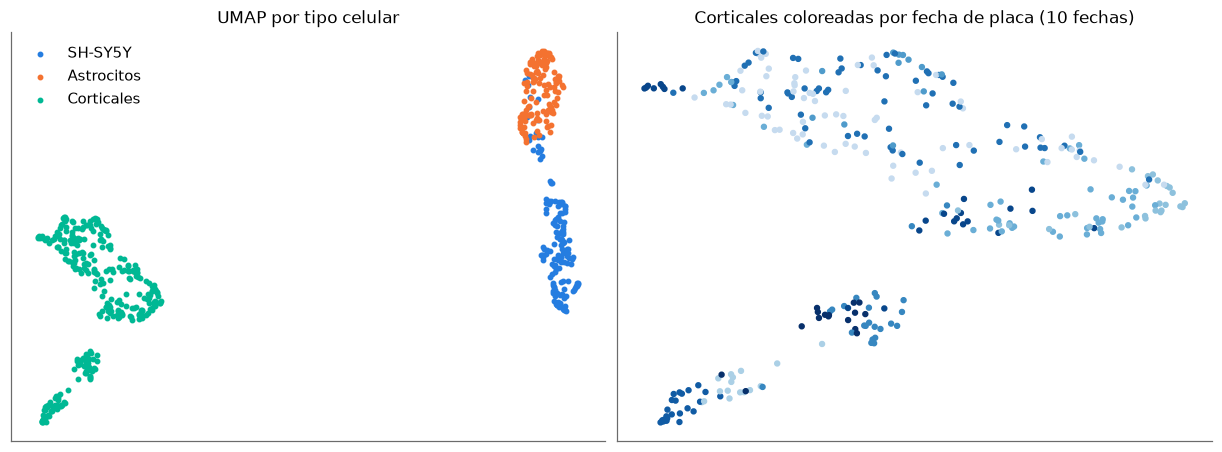

Exactitud de clasificación del tipo celular (5 pliegues): **0.988**.

,tipo,fechas,exactitud,clase mayoritaria,p (permutación),media con permutación
0,Astrocitos,5,0.557,0.351,0.032,0.232
1,Corticales,10,0.534,0.212,0.032,0.143
2,SH-SY5Y,3,0.626,0.335,0.032,0.328


In [12]:
b = need("eda/seg/batch_effects.pkl")
ids = b["ids"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for t in TYPES:
    m = images.loc[ids, "cell_type"].to_numpy() == t
    axes[0].scatter(b["umap"][m, 0], b["umap"][m, 1], s=8, color=CELL_COLORS[t], label=CELL_NAMES[t])
axes[0].set(title="UMAP por tipo celular", xticks=[], yticks=[]); axes[0].legend()
sub = images.loc[ids]
m = sub.cell_type.to_numpy() == "cort"
codes = pd.factorize(sub.sample_date[m])[0]
axes[1].scatter(b["umap"][m, 0], b["umap"][m, 1], s=10, c=codes, cmap="Blues", vmin=-3)
axes[1].set(title="Corticales coloreadas por fecha de placa (10 fechas)", xticks=[], yticks=[])
plt.show()
w = b["date_within_type"].copy(); w["cell_type"] = w.cell_type.map(CELL_NAMES)
display(Markdown(f"Exactitud de clasificación del tipo celular (5 pliegues): **{b['cell_type_acc']:.3f}**."))
w.rename(columns={"cell_type": "tipo", "n_dates": "fechas", "acc": "exactitud", "majority": "clase mayoritaria",
                  "perm_mean": "media con permutación", "perm_p": "p (permutación)"})

La fecha de placa deja una huella detectable en las tres líneas celulares; con 30 permutaciones, el menor valor p posible es 1/31 ≈ 0.032. La partición agrupa por `sample_id`, y las imágenes de una misma fecha pueden caer en particiones distintas. Esa decisión fue obligada: cada fecha contiene un solo tipo celular, y agrupar por fecha deja muy pocos grupos para estratificar por tipo (5, 10 y 3 fechas). La consecuencia es una condición de validez: el rendimiento de test mide la generalización a muestras nuevas de fechas ya vistas, no a placas nuevas. El experimento *leave-one-cell-type-out* del capítulo de robustez mide el caso de dominio nuevo.

La homogeneidad entre placas se resume con el ICC(1) de la intensidad media por fecha:

In [13]:
h = need("eda/seg/homogeneity.pkl")
pd.DataFrame(h).T.rename(index=CELL_NAMES)[["icc_mean_intensity_by_date", "cv_plate_mean_intensity", "count_cv", "count_gini", "n_images"]].rename(
    columns={"icc_mean_intensity_by_date": "ICC(1) intensidad por fecha", "cv_plate_mean_intensity": "CV entre placas",
             "count_cv": "CV del conteo", "count_gini": "Gini del conteo", "n_images": "imágenes"})

,ICC(1) intensidad por fecha,CV entre placas,CV del conteo,Gini del conteo,imágenes
global,0.144,1.865e-04,1.251,0.583,606.0
Astrocitos,0.104,1.203e-04,0.795,0.339,131.0
Corticales,0.105,1.688e-04,0.489,0.251,320.0
SH-SY5Y,0.019,8.985e-05,0.442,0.249,155.0


La intensidad media es casi idéntica entre placas (CV del orden de 10⁻⁴): las imágenes llegan con la media igualada cerca de 128. Un ICC de 0.02 a 0.14 indica que la fecha explica una fracción pequeña de la varianza de la intensidad media. La huella de lote que detecta el clasificador está, entonces, en la textura y la morfología, no en el brillo. Normalizar por percentiles por imagen no la elimina.

## Calidad de anotación

Medimos tres señales. Primero, la fragmentación: proporción de anotaciones (muestra de 3000) con más de una componente conexa.

In [14]:
fr = need("eda/seg/annotation_fragments.pkl")
fr.groupby(fr.cell_type.map(CELL_NAMES)).n_components.apply(lambda s: (s > 1).mean()).mul(100).round(1).to_frame("anotaciones fragmentadas (%)")

,anotaciones fragmentadas (%)
cell_type,
Astrocitos,22.9
Corticales,0.7
SH-SY5Y,2.3


Segundo, las instancias diminutas: menos de 20 píxeles, por debajo del tamaño de un cuerpo celular. Son menos del 0.2 % en todos los tipos.

In [15]:
inst.groupby(inst.cell_type.map(CELL_NAMES)).area.apply(lambda a: pd.Series({"< 20 px (%)": round(100 * (a < 20).mean(), 3), "mínimo (px)": a.min()})).unstack()

,< 20 px (%),mínimo (px)
cell_type,,
Astrocitos,0.019,10.0
Corticales,0.102,6.0
SH-SY5Y,0.117,1.0


Tercero, una inspección visual de 12 recortes de 260 × 352 píxeles (cuatro por tipo, semilla fija; {numref}`fig-revision`). Contamos como error evidente un cuerpo celular con la morfología del tipo y sin contorno, o un contorno con segmentos rectos que cruzan fondo. Los objetos redondos y brillantes sin prolongaciones se consideran restos y no cuentan.

```{figure} images/gen/seg_revision_anotacion.png
:name: fig-revision
:width: 100%

*Recortes usados para estimar la cota de ruido de anotación.* Elaboración propia con datos de Sartorius.
```

In [16]:
rev = need("eda/seg/annotation_review.pkl")["table"]
k, n = int(rev.error_evidente.sum()), len(rev)
lo, hi = stats.beta.ppf(0.025, k, n - k + 1), stats.beta.ppf(0.975, k + 1, n - k)
display(rev.assign(tipo=rev.cell_type.map(CELL_NAMES))[["id", "tipo", "celula_sin_anotar", "artefacto_contorno", "nota"]])
display(Markdown(f"Recortes con al menos un error evidente: **{k} de {n}** ({k / n:.0%}; IC 95 % de Clopper–Pearson [{lo:.0%}, {hi:.0%}])."))

,id,tipo,celula_sin_anotar,artefacto_contorno,nota
0,1f81ad0e1fb6,SH-SY5Y,1,0,células con cuerpo y neuritas visibles sin con...
1,836e5872684a,SH-SY5Y,1,0,varias células del grupo central sin contorno
2,1e7ac54a9422,SH-SY5Y,0,0,"objetos redondos brillantes sin contorno, comp..."
3,bfb878cd992e,SH-SY5Y,1,0,células parcialmente contorneadas en el borde ...
4,194f7e69779b,Astrocitos,0,0,una célula anotada; el resto son restos redondos
5,7570dd2d34bb,Astrocitos,0,1,contornos con segmentos rectos que atraviesan ...
6,1874b96fd317,Astrocitos,0,0,sin errores evidentes
7,cca71932b689,Astrocitos,1,1,célula aplanada con contorno poligonal y segme...
8,22e0c43da285,Corticales,0,0,"restos redondos sin anotar, coherente con el p..."
9,7b67cd233fcd,Corticales,0,0,sin errores evidentes


Recortes con al menos un error evidente: **5 de 12** (42%; IC 95 % de Clopper–Pearson [15%, 72%]).

La cota es gruesa: cuenta recortes con algún error y no la proporción de células mal anotadas, y la muestra es pequeña. Aun así, apunta a dos fuentes de ruido con mecanismos distintos. En SH-SY5Y faltan contornos de células en grupos densos, lo que penaliza como falsos positivos detecciones correctas. En astrocitos aparecen contornos poligonales con segmentos rectos, coherentes con el 23 % de anotaciones fragmentadas. Ese ruido limita el AP alcanzable en astrocitos con cualquier modelo.

## Auditoría de fuga

Calculamos el *hash* perceptual (pHash, 64 bits) de las 606 imágenes y buscamos pares a distancia de Hamming de 6 o menos.

In [17]:
ph = need("eda/seg/phash.pkl")
pairs = ph["pairs"]
display(pairs)
split = images.split
display(Markdown(f"Pares casi idénticos: **{len(pairs)}**; del mismo `sample_id`: **{int(pairs.same_sample.sum())}**; "
                 f"que cruzan particiones: **{int((~pairs.same_split).sum())}**."))
grp = images.groupby("sample_id").split.nunique()
display(Markdown(f"`sample_id` repartidos en más de una partición: **{int((grp > 1).sum())}** de {len(grp)}."))

,a,b,hamming,same_sample,same_split,split_a,split_b
0,01ae5a43a2ab,afbcea22fc2a,4,True,True,train,train
1,01ae5a43a2ab,b0c3bd326249,4,True,True,train,train
2,1242e4ec6ef3,95de75855f80,6,True,True,train,train
3,5286d9ca0f92,dac9a173832d,4,True,True,test,test
4,afbcea22fc2a,b0c3bd326249,4,True,True,train,train


Pares casi idénticos: **5**; del mismo `sample_id`: **5**; que cruzan particiones: **0**.

`sample_id` repartidos en más de una partición: **0** de 403.

Los cinco pares casi idénticos comparten `sample_id` y por eso caen en la misma partición. Ningún grupo cruza particiones.

## Desbalance y efecto esperado sobre la métrica global

La partición conserva la proporción de tipos celulares en entrenamiento, validación y prueba.

In [18]:
ct = pd.crosstab(images.tipo, images.split)[["train", "val", "test"]]
ct.loc["Total"] = ct.sum()
ct

split,train,val,test
tipo,,,
Astrocitos,89,21,21
Corticales,224,48,48
SH-SY5Y,108,23,24
Total,421,92,93


Para dimensionar el efecto del desbalance sobre la métrica global, supongamos un modelo con AP por tipo $a_{\text{shsy5y}}, a_{\text{astro}}, a_{\text{cort}}$. El AP global por imagen es $\sum_t w_t a_t$ con pesos $w = (0.26, 0.22, 0.53)$, la proporción de imágenes de cada tipo. Una mejora de 0.05 en SH-SY5Y, el tipo con más células, sube el AP global solo en 0.013. La misma mejora en corticales lo sube en 0.026. Por eso el AP global no basta para comparar modelos que difieren en un solo tipo.

## Interpretación cuantitativa

- **Homogeneidad.** La intensidad media es homogénea entre placas (CV ≈ 10⁻⁴; ICC(1) por fecha de 0.02 a 0.14). Hay efecto de lote en la textura: la fecha se predice por encima del azar dentro de cada tipo (p = 0.032 con 30 permutaciones). El tipo celular se predice con exactitud de 0.99.
- **Desbalance del conteo.** Gini 0.58 y CV 1.25 a nivel global, con medianas de 30, 73 y 324 células por imagen en corticales, astrocitos y SH-SY5Y.
- **Tamaño.** Mediana del área de 187, 206 y 646 píxeles (SH-SY5Y, corticales, astrocitos). Percentil 1 del lado de caja de 8.5 px; el 5 % de las cajas mide menos de 11 px de lado.
- **Ruido y artefactos.** El 5 % de las anotaciones está fragmentado (23 % en astrocitos). La inspección visual encontró error evidente en 5 de 12 recortes. La saturación es nula.

## Decisiones de diseño derivadas del EDA

1. **Resolución nativa con *padding* a 544 × 704 y recortes de 256 sin reescalar.** Al reducir el lado corto a 256 píxeles, el 7.3 % de las células de SH-SY5Y quedaría por debajo de 20 píxeles.
2. **Objetivo de tres clases con borde y marcadores por *h-maxima*.** El 73 % de las células toca a otra.
3. **Anclas de Mask R-CNN de 12, 24, 48, 96 y 192 píxeles con razones 0.5, 1 y 2, y hasta 1000 detecciones por imagen.** El lado de caja va de 8.5 a 89 píxeles entre los percentiles 1 y 99, la excentricidad mediana de los astrocitos es 0.95 y hay imágenes con 790 células.
4. **Partición agrupada por `sample_id` y estratificada por tipo.** Los casi duplicados comparten `sample_id`, y cada fecha tiene un solo tipo celular.
5. **Normalización por percentiles 1–99 por imagen.** El contraste mediano va de 54 (astrocitos) a 94 (corticales), y la información útil está en la textura.
6. **Tamaño mínimo de instancia entre 10 y 30 píxeles en la rejilla de post-proceso.** El percentil 1 del área es de 46 a 98 píxeles según el tipo; un umbral de 30 elimina fragmentos sin perder células reales.
7. **Evaluación estratificada por tipo, densidad y tamaño.** Corticales dominan las imágenes y SH-SY5Y las células.
8. ***Leave-one-cell-type-out* para medir el cambio de dominio.** El tipo celular es casi perfectamente separable en el espacio de *embeddings*.